# 05 · Article 14 reporting: deadline engine, tabletop scoring and staffing simulation (E5)
**Supports:** RQ1, concept note §8 *reporting preparedness*. The 24 h / 72 h / final-report clocks follow Art. 14(2) and 14(4); "without undue delay" is stricter than the outer limit and is **not** modelled. Planning aid, not legal advice.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from crasme import plotting; plotting.use()
pd.set_option('display.precision', 3); pd.set_option('display.width', 140)
from datetime import datetime, timedelta, timezone
from crasme.reporting import *

## 1 · Inject set (facilitator answer key reviewed by a legal specialist before use)

In [2]:
T0 = datetime(2026, 11, 6, 16, 40, tzinfo=timezone.utc)   # Friday afternoon on purpose
injects = [
  Inject('I1', 'Customer forwards logs showing exploitation of auth bypass in gateway fw 2.3', True, EventType.EXPLOITED_VULNERABILITY, T0, T0+timedelta(days=4)),
  Inject('I2', 'Researcher reports XSS with PoC; no evidence of exploitation', False, None, T0+timedelta(hours=2)),
  Inject('I3', 'Update server compromised; malicious firmware signed and pushed to 3% of fleet', True, EventType.SEVERE_INCIDENT, T0+timedelta(hours=20)),
  Inject('I4', 'Upstream library maintainer publishes advisory; CISA KEV lists it as exploited; library used in product', True, EventType.EXPLOITED_VULNERABILITY, T0+timedelta(hours=30), T0+timedelta(days=9)),
  Inject('I5', 'Internal pentest finds hard-coded debug credential in unreleased build', False, None, T0+timedelta(hours=40)),
]
pd.DataFrame([{'id': i.inject_id, 'reportable (key)': i.reportable, 'type': i.event_type.value if i.event_type else '-', 'description': i.description} for i in injects])

,id,reportable (key),type,description
0,I1,True,actively_exploited_vulnerability,Customer forwards logs showing exploitation of...
1,I2,False,-,Researcher reports XSS with PoC; no evidence o...
2,I3,True,severe_incident,Update server compromised; malicious firmware ...
3,I4,True,actively_exploited_vulnerability,Upstream library maintainer publishes advisory...
4,I5,False,-,Internal pentest finds hard-coded debug creden...


Note for I5: not a reportable event (product not made available), but it is a release blocker under Annex I Part I(2)(a). I4 also triggers Art. 13(6) (report to maintainer is moot — already public — but due diligence and user information apply).

In [3]:
resp = [
  TeamResponse('I1', True, T0+timedelta(hours=5), {'early_warning': T0+timedelta(hours=22), 'notification': T0+timedelta(hours=70), 'final_report': T0+timedelta(days=15)}, 9, 12),
  TeamResponse('I2', True, T0+timedelta(hours=3)),
  TeamResponse('I3', True, T0+timedelta(hours=26), {'early_warning': T0+timedelta(hours=47), 'notification': T0+timedelta(hours=95)}, 7, 12),
  TeamResponse('I4', True, T0+timedelta(hours=33), {'early_warning': T0+timedelta(hours=50), 'notification': T0+timedelta(hours=99), 'final_report': T0+timedelta(days=20)}, 10, 12),
  TeamResponse('I5', False, T0+timedelta(hours=41)),
]
score = score_tabletop(injects, resp)
print('decision accuracy', score['decision_accuracy'], '| stage timeliness', round(score['stage_timeliness'], 2))
pd.DataFrame(score['rows'])

decision accuracy 0.8 | stage timeliness 0.67


,inject,decision_correct,decision_latency_h,early_warning_on_time,early_warning_margin_h,notification_on_time,notification_margin_h,final_report_on_time,final_report_margin_h,completeness
0,I1,True,5.0,True,2.0,True,2.0,True,72.0,0.750
1,I2,False,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,I3,True,6.0,False,-3.0,False,-3.0,False,NaN,0.583
3,I4,True,3.0,True,4.0,True,3.0,True,72.0,0.833
4,I5,True,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


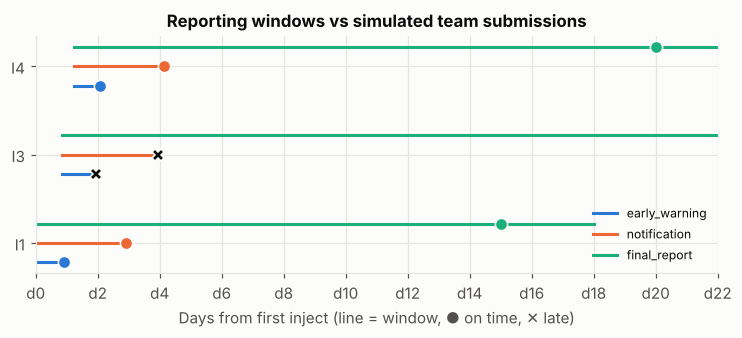

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.8))
for k, inj in enumerate([i for i in injects if i.reportable]):
    r = next(x for x in resp if x.inject_id == inj.inject_id)
    clk = ReportingClock(inj.event_type, inj.released_at, inj.corrective_measure_at, r.submissions.get('notification'))
    for j, (stage, due) in enumerate(clk.deadlines().items()):
        if due is None: continue
        h = lambda d: (d - T0).total_seconds()/3600
        ax.plot([h(inj.released_at), h(due)], [k + j*0.22]*2, color=plotting.SERIES[j], lw=2, label=stage if k == 0 else None)
        if stage in r.submissions:
            sub = h(r.submissions[stage]); late = r.submissions[stage] > due
            ax.plot(sub, k + j*0.22, 'X' if late else 'o', color=plotting.INK if late else plotting.SERIES[j], markersize=8, markeredgecolor=plotting.SURFACE)
ax.set_yticks([0.22, 1.22, 2.22], ['I1', 'I3', 'I4']); ax.set_xlabel('Days from first inject (line = window, ● on time, ✕ late)')
ax.set_xlim(0, 24*22); ax.set_xticks(range(0, 24*22+1, 48), [f'd{d}' for d in range(0, 23, 2)]); ax.legend(loc='lower right', fontsize=8); ax.set_title('Reporting windows vs simulated team submissions'); plt.show()

## 2 · Staffing simulation: probability of missing the 24 h early warning
Assumptions (replace with pilot measurements): awareness time uniform over the week; triage starts at next working hour (no on-call) or within ~1 h (on-call); triage + drafting ~ lognormal with median 4 h.

In [5]:
rng = np.random.default_rng(11)
def miss_rate(on_call, n=20000):
    start = rng.uniform(0, 7*24, n)                      # hour of week, Mon 00:00 = 0
    def next_working(h):
        day, hr = int(h // 24), h % 24
        if on_call: return h + rng.exponential(1.0)
        while True:
            if day % 7 < 5 and 8 <= hr < 17: return day*24 + hr
            if day % 7 < 5 and hr < 8: return day*24 + 8
            day, hr = day + 1, 0.0
    begin = np.array([next_working(h) for h in start])
    work = rng.lognormal(np.log(4), 0.6, n)
    return float(((begin - start + work) > 24).mean())
res = pd.DataFrame({'model': ['office hours only', 'on-call rota'], 'P(miss 24 h)': [miss_rate(False), miss_rate(True)]}); res

,model,P(miss 24 h)
0,office hours only,0.266
1,on-call rota,0.002


**Use in the paper:** compare simulated miss-rates with observed tabletop timeliness per SME; the staffing variable is a candidate explanatory factor for RQ5.